In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from neural_recording_chain.frozen_noise import make_frozen_noise
from neural_recording_chain.pyramidal_cell import simulate_pyramidal_cell
from neural_recording_chain.spikes import find_spikes
from neural_recording_chain.electrode import extracellular_potential

#different input (seed=1 instead of seed=0) 
input_theory, hidden_state = make_frozen_noise(duration_ms=60000, dt_ms=0.05, seed=1)
result = simulate_pyramidal_cell(input_theory, dt_ms=0.05)
spike_times, spike_heights = find_spikes(result["v_soma_mV"], result["time_ms"])
v_electrode_uV = extracellular_potential(result["v_soma_mV"], result["v_dend_mV"])

np.savez(
    "../data/processed/simulation_60s_seed1.npz",
    time_ms=result["time_ms"],
    v_electrode_uV=v_electrode_uV,
    spike_times=spike_times,
    spike_heights=spike_heights,
)
print("true spikes:", len(spike_times))

In [3]:
from neural_recording_chain.noise import thermal_noise_uV, background_noise_uV, slow_wave_uV
from neural_recording_chain.filter import bandpass_filter
from neural_recording_chain.adc import digitise
from neural_recording_chain.detector import detect_spikes
from neural_recording_chain.events import group_into_events
from neural_recording_chain.burst_label import wobble_after

# recording A: the first simulation, as the chip sees it
data_a = np.load("../data/processed/simulation_60s.npz")
time_a = data_a["time_ms"]
n_samples = len(data_a["v_electrode_uV"])

recording_a = (data_a["v_electrode_uV"] + thermal_noise_uV(n_samples, dt_ms=0.05)
               + background_noise_uV(n_samples, dt_ms=0.05) + slow_wave_uV(n_samples, dt_ms=0.05))
filtered_a = bandpass_filter(recording_a, dt_ms=0.05)
chip_signal_a, step_uV = digitise(filtered_a, n_bits=8, input_range_uV=500.0)
detections_a, threshold_uV = detect_spikes(chip_signal_a, time_a, threshold_factor=4.5, min_gap_ms=3.0)

# the chip groups its own detections with the same 10 ms rule
detected_events_a = group_into_events(detections_a)
print("detected events:", len(detected_events_a))

first_event = detected_events_a[0]
print("first event at", round(first_event[0], 1), "ms, with", len(first_event), "detections")
print("wobble after it:", round(wobble_after(chip_signal_a, time_a, first_event[0]), 1), "uV")

detected events: 195
first event at 24.8 ms, with 2 detections
wobble after it: 25.4 uV


one-detection events that are single spikes: 32
one-detection events that are bursts:        107
typical wobble, single spikes: 16.1 uV
typical wobble, bursts:        26.0 uV


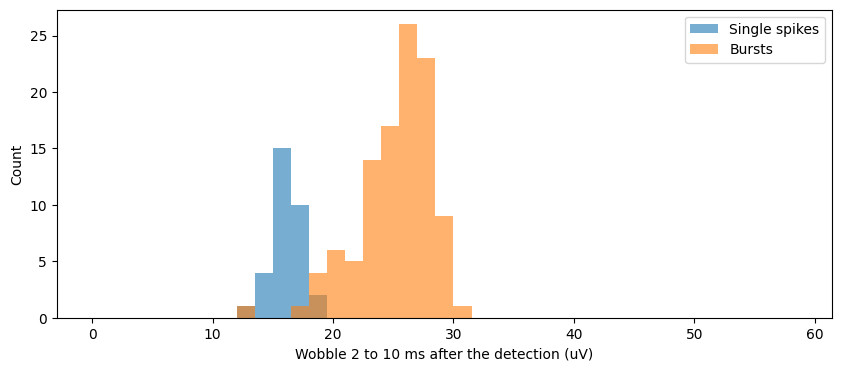

In [4]:
from neural_recording_chain.burst_label import label_event, true_type

true_events_a = group_into_events(data_a["spike_times"])

single_wobbles = []
burst_wobbles = []

for detected_event in detected_events_a:
    if len(detected_event) == 1:
        wobble = wobble_after(chip_signal_a, time_a, detected_event[0])
        kind = true_type(detected_event, true_events_a)
        if kind == "single":
            single_wobbles.append(wobble)
        if kind == "burst":
            burst_wobbles.append(wobble)

print("one-detection events that are single spikes:", len(single_wobbles))
print("one-detection events that are bursts:       ", len(burst_wobbles))
print("typical wobble, single spikes:", round(np.median(single_wobbles), 1), "uV")
print("typical wobble, bursts:       ", round(np.median(burst_wobbles), 1), "uV")

fig, ax = plt.subplots(figsize=(10, 4))
bins = np.arange(0, 60, 1.5)
ax.hist(single_wobbles, bins=bins, alpha=0.6, label="Single spikes")
ax.hist(burst_wobbles, bins=bins, alpha=0.6, label="Bursts")
ax.set_xlabel("Wobble 2 to 10 ms after the detection (uV)")
ax.set_ylabel("Count")
ax.legend()
plt.show()

In [5]:
best_cutoff = 0
best_correct = 0

for cutoff in np.arange(10, 40, 0.5):
    correct = 0
    total = 0
    for detected_event in detected_events_a:
        kind = true_type(detected_event, true_events_a)
        if kind == "none":
            continue
        guess = label_event(detected_event, chip_signal_a, time_a, cutoff)
        total = total + 1
        if guess == kind:
            correct = correct + 1

    if correct > best_correct:
        best_correct = correct
        best_cutoff = cutoff

print("best cut-off:", best_cutoff, "uV")
print("correct on recording A:", best_correct, "of", total)

best cut-off: 18.5 uV
correct on recording A: 192 of 194


detected events in recording B: 163
single spikes labelled right: 23 of 23
bursts labelled right:        128 of 138
overall: 93.8 % right
always guessing 'burst': 85.7 % right


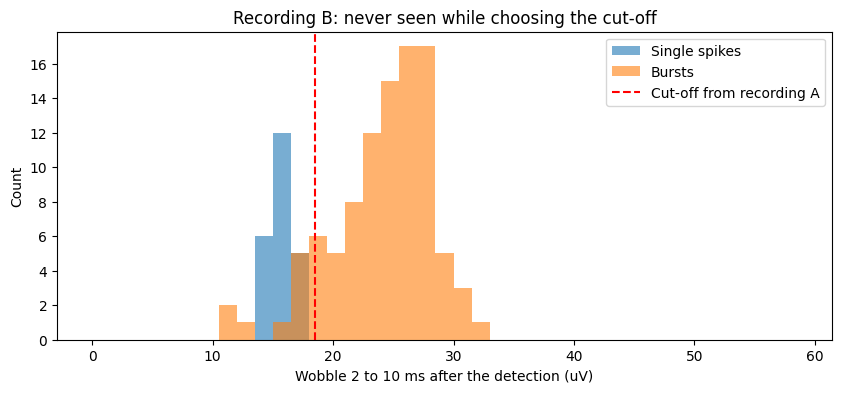

In [6]:
# recording B: the fresh simulation, never used to choose the cut-off
data_b = np.load("../data/processed/simulation_60s_seed1.npz")
time_b = data_b["time_ms"]
n_samples_b = len(data_b["v_electrode_uV"])

recording_b = (data_b["v_electrode_uV"] + thermal_noise_uV(n_samples_b, dt_ms=0.05, seed=2)
               + background_noise_uV(n_samples_b, dt_ms=0.05, seed=3) + slow_wave_uV(n_samples_b, dt_ms=0.05))
filtered_b = bandpass_filter(recording_b, dt_ms=0.05)
chip_signal_b, step_uV = digitise(filtered_b, n_bits=8, input_range_uV=500.0)
detections_b, threshold_uV = detect_spikes(chip_signal_b, time_b, threshold_factor=4.5, min_gap_ms=3.0)

detected_events_b = group_into_events(detections_b)
true_events_b = group_into_events(data_b["spike_times"])

singles_right = 0
singles_total = 0
bursts_right = 0
bursts_total = 0
single_wobbles_b = []
burst_wobbles_b = []

for detected_event in detected_events_b:
    kind = true_type(detected_event, true_events_b)
    if kind == "none":
        continue
    guess = label_event(detected_event, chip_signal_b, time_b, best_cutoff)

    if kind == "single":
        singles_total = singles_total + 1
        if guess == "single":
            singles_right = singles_right + 1
    if kind == "burst":
        bursts_total = bursts_total + 1
        if guess == "burst":
            bursts_right = bursts_right + 1

    # keep the wobbles of one-detection events for the plot
    if len(detected_event) == 1:
        wobble = wobble_after(chip_signal_b, time_b, detected_event[0])
        if kind == "single":
            single_wobbles_b.append(wobble)
        if kind == "burst":
            burst_wobbles_b.append(wobble)

all_right = singles_right + bursts_right
all_total = singles_total + bursts_total
print("detected events in recording B:", len(detected_events_b))
print("single spikes labelled right:", singles_right, "of", singles_total)
print("bursts labelled right:       ", bursts_right, "of", bursts_total)
print("overall:", round(100 * all_right / all_total, 1), "% right")
print("always guessing 'burst':", round(100 * bursts_total / all_total, 1), "% right")

fig, ax = plt.subplots(figsize=(10, 4))
bins = np.arange(0, 60, 1.5)
ax.hist(single_wobbles_b, bins=bins, alpha=0.6, label="Single spikes")
ax.hist(burst_wobbles_b, bins=bins, alpha=0.6, label="Bursts")
ax.axvline(best_cutoff, color="red", linestyle="--", label="Cut-off from recording A")
ax.set_xlabel("Wobble 2 to 10 ms after the detection (uV)")
ax.set_ylabel("Count")
ax.set_title("Recording B: never seen while choosing the cut-off")
ax.legend()
plt.show()